<a href="https://colab.research.google.com/github/junkim-researcher/turboquant-study1/blob/main/notebooks/exp3_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3단계: 모델 실험 (perplexity) + 키 진단

## ⚠️ 실행 전에 GPU 켜기
메뉴 **[런타임] → [런타임 유형 변경] → 하드웨어 가속기 `T4 GPU` → [저장]**

그다음 **[런타임] → [모두 실행]** (약 10~20분)

끝나면 **[파일] → [GitHub에 사본 저장]** → 경로 `notebooks/exp3_colab.ipynb` 그대로 → **[확인]**

In [1]:
# 1) GPU 확인
!nvidia-smi -L || echo '⚠️ GPU가 없습니다. [런타임]→[런타임 유형 변경]에서 T4 GPU를 켜고 다시 실행하세요.'

GPU 0: Tesla T4 (UUID: GPU-2311cfdf-9cbc-27df-3af9-b0dde828f164)


In [2]:
# 2) 코드 내려받기
!rm -rf /content/turboquant-study1
!git clone -q https://github.com/junkim-researcher/turboquant-study1.git /content/turboquant-study1
%cd /content/turboquant-study1
!git log --oneline -1

/content/turboquant-study1
53ae66e (HEAD -> main, origin/main, origin/HEAD) 2단계 결과 정리, 3단계 perplexity 실험과 키 진단 코드


In [3]:
# 3) 글꼴과 라이브러리 준비
!apt-get -qq install -y fonts-noto-cjk > /dev/null 2>&1
!rm -rf ~/.cache/matplotlib
!pip -q install "transformers>=4.48" datasets
import transformers, torch; print('transformers', transformers.__version__, '| torch', torch.__version__)

transformers 5.22.1 | torch 2.14.1+cu130


In [4]:
# 4) 3단계 실험 실행 (B0 + 설정 9개 × 시드 5개 × 조각 40개)
!python exp3_ppl.py 2>&1 | grep -v -i -E 'warn|hf_token|secret'

Generating validation split: 100%|██████████| 3760/3760 [00:00<00:00, 607378.51 examples/s]
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors
모델 Qwen/Qwen2.5-0.5B  {'n_layers': 24, 'n_heads': 14, 'n_kv_heads': 2, 'head_dim': 64}  장치 cuda  조각 40개 × 1024토큰
끼어들기 검사: 기본 구현과의 출력 최대 차이 = 9.107589721679688e-05
키 진단 완료 (34초)
B0 perplexity 13.228 (45초)
  v_only_b2  perplexity    15.265  (105초)
  v_only_b3  perplexity    13.593  (166초)
  v_only_b4  perplexity    13.310  (229초)
  k_mse_b2   perplexity  1203.468  (294초)
  k_mse_b3   perplexity   336.958  (359초)
  k_mse_b4   perplexity   144.788  (424초)
  k_prod_b2  perplexity  8713.836  (490초)
  k_prod_b3  perplexity  2410.997  (555초)
  k_prod_b4  perplexity   598.365  (621초)
완료: 621.9초


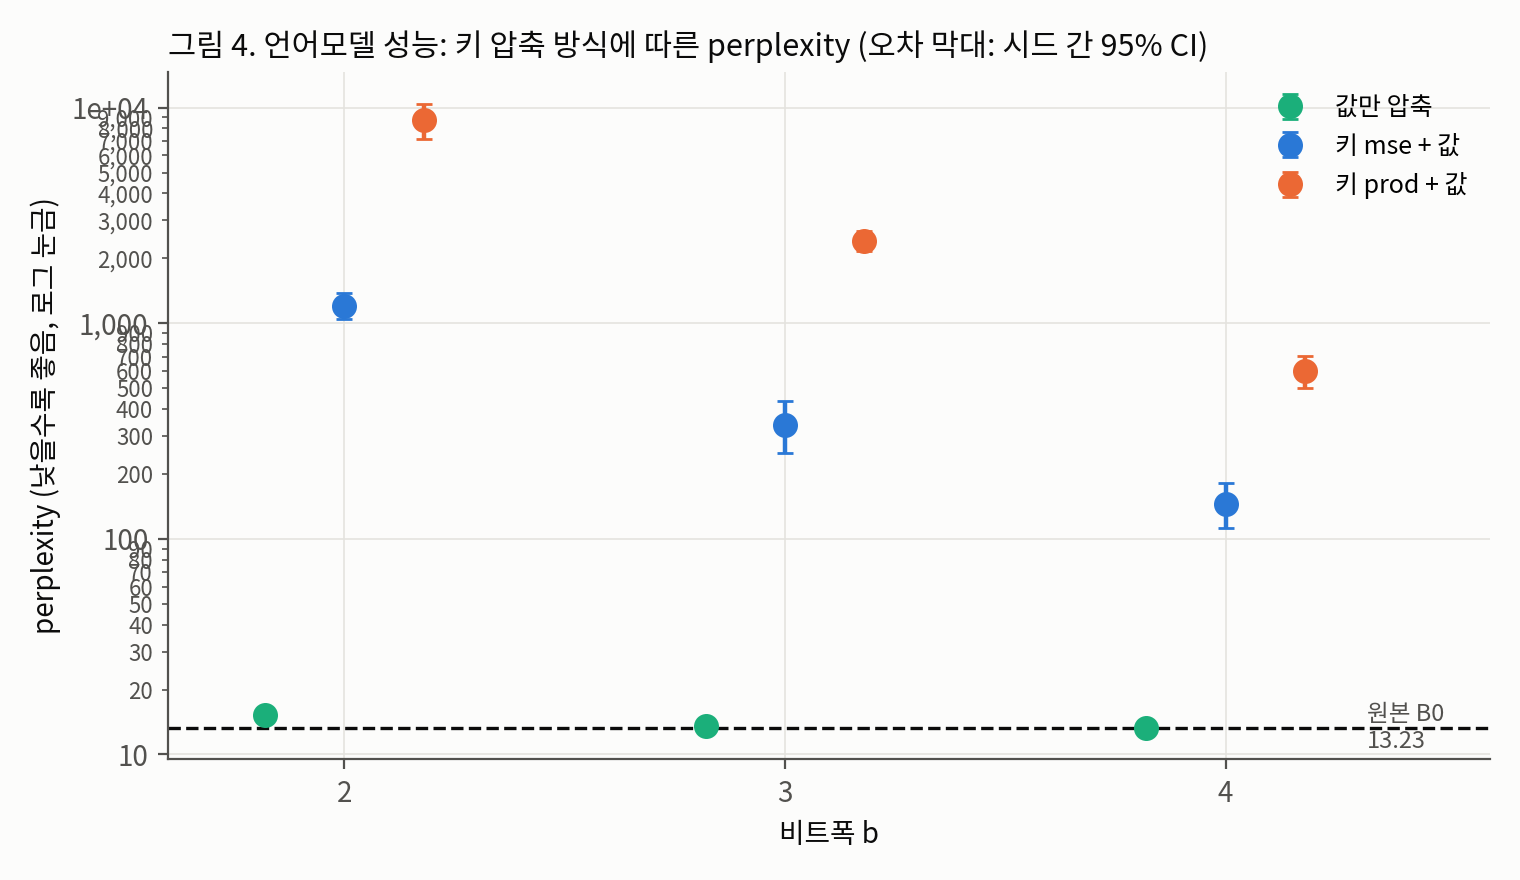

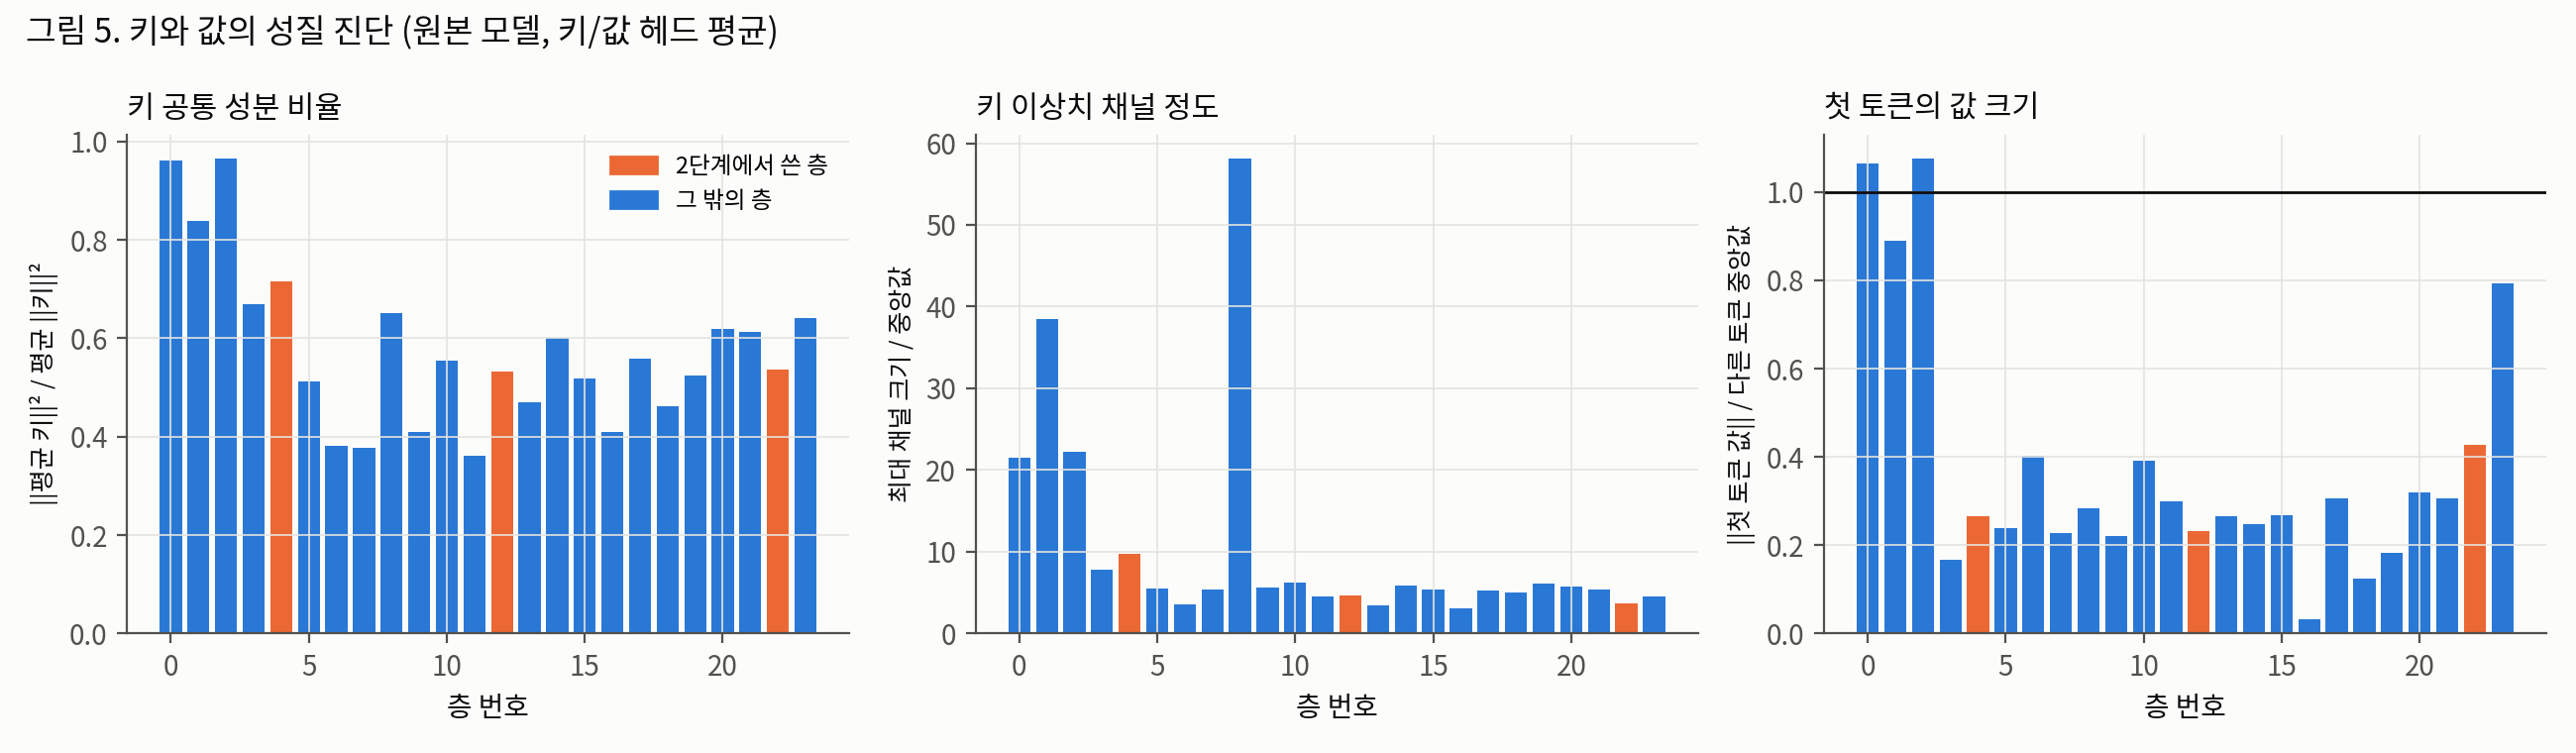

In [5]:
# 5) 그림 보기
from IPython.display import Image, display
display(Image('figures/fig4_perplexity.png', width=800))
display(Image('figures/fig5_kv_diagnostics.png', width=1000))

In [6]:
# 6) 판정 요약
!python summarize_exp3.py

 3단계 판정 요약   3단계 perplexity + 키 진단
 모델 Qwen/Qwen2.5-0.5B  시드 5개  조각 40개 × 1024토큰  장치 Tesla T4
 끼어들기 검사(기본 구현과의 출력 차이): 9.107589721679688e-05
 [1] perplexity (낮을수록 좋음)   원본 B0 = 13.228
  b |            값만 압축 |          키 mse + 값 |         키 prod + 값
  2 |   15.265 ( +15.4%) |  1203.468 (+8998.0%) |  8713.836 (+65775.1%)
  3 |   13.593 (  +2.8%) |   336.958 (+2447.3%) |  2410.997 (+18126.7%)
  4 |   13.310 (  +0.6%) |   144.788 (+994.6%) |   598.365 (+4423.5%)
------------------------------------------------------------------------------------
 [2] 조각 단위 대응 비교 (토큰당 손실 차이, 본페로니 0.0167)
   b=2  prod − mse = +1.9797 [+1.8599, +2.0995]  p_t=2.5e-30 p_윌콕슨=1.8e-12  유의   | mse − B0 = +4.5106 (유의)
   b=3  prod − mse = +1.9678 [+1.8032, +2.1324]  p_t=4.4e-25 p_윌콕슨=1.8e-12  유의   | mse − B0 = +3.2376 (유의)
   b=4  prod − mse = +1.4189 [+1.2560, +1.5818]  p_t=3.6e-20 p_윌콕슨=1.8e-12  유의   | mse − B0 = +2.3929 (유의)
------------------------------------------------------------------------------------
 [3]

In [8]:
# 7) (보관용) 결과 JSON을 노트북 출력에 남기기 → GitHub에 저장하면 Claude가 원자료를 읽을 수 있음
import json
r = json.load(open('results/exp3_results.json', encoding='utf-8'))
print(json.dumps({k: r[k] for k in ('results', 'per_chunk_nll', 'env', 'runtime_sec')}, ensure_ascii=False))

{"results": {"B0": {"ppl": 13.227823491411627, "mean_nll": 2.5823224514722822}, "v_only_b2": {"ppl": 15.264801149352747, "mean_nll": 2.7255495995283128, "ppl_increase_pct": 15.39918989139566, "ppl_per_seed": [15.323937250415133, 15.078785598454532, 15.24058921036965, 15.392842386358286, 15.28968172848641], "ppl_seed_ci95": [15.118648235160478, 15.41168623447313]}, "v_only_b3": {"ppl": 13.593020463344383, "mean_nll": 2.609556459784508, "ppl_increase_pct": 2.760824350051738, "ppl_per_seed": [13.580713368580147, 13.558383960585012, 13.599764282627397, 13.608473498409392, 13.617850084535762], "ppl_seed_ci95": [13.563575724715502, 13.622498353179584]}, "v_only_b4": {"ppl": 13.309836689024348, "mean_nll": 2.58850336253643, "ppl_increase_pct": 0.6200052311400306, "ppl_per_seed": [13.317830695058735, 13.299254624784538, 13.312371074063114, 13.314010026778993, 13.305725163587825], "ppl_seed_ci95": [13.300700717968825, 13.318975915740458]}, "k_mse_b2": {"ppl": 1203.4680117028136, "mean_nll": 7.0